# 독성 모델 성능 개선 2차: 튜닝·복합 kernel·스태킹·반복 CV

2026-10-02 · 클로드의 07_개선 작업을 검토하고 기존 캐시를 재사용했다. **제출하지 않았다.** 1차 파일은 `08_재개선/1차백업/predict_output_서혁인.csv`에 보존하고, 루트 파일에는 2차 결과를 반영했다. 새 제출용 파일은 `08_재개선/제출용/predict_output_서혁인.csv`다.

목표는 과제/리더보드의 positive=1=비독성 F1이다. 랜덤 층화 CV를 주요 근사로 사용하고 연결구조 그룹 CV를 보조로 확인한다. OOF와 hidden Leaderboard 점수는 구별한다.

In [1]:
from pathlib import Path
import sys,os,json,hashlib,tempfile
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'toxicity-matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from sklearn.metrics import f1_score,accuracy_score,roc_auc_score,RocCurveDisplay,PrecisionRecallDisplay
cwd=Path.cwd().resolve()
ROOT=next(p for p in [cwd,*cwd.parents,*[x for x in cwd.iterdir() if x.is_dir()]] if (p/'02_데이터/train.csv').exists())
DEST=ROOT/'08_재개선'
sys.path.insert(0,str(DEST))
import improve
improve.self_check()
selection=json.loads((DEST/'ensemble_selection.json').read_text())
validation=json.loads((DEST/'validation.json').read_text())
print('선택 방법:',selection['name'])
print('전체 검증:',validation)

Matplotlib is building the font cache; this may take a moment.


PASS: F1 positive=safe, threshold plateau, kernel, convex blend
선택 방법: logistic_C0.1
전체 검증: {'csv_rows': 927, 'csv_columns': ['SMILES', 'output'], 'smiles_exact_and_order_preserved': True, 'previous_submission_unchanged': True, 'protected_sources_unchanged': True, 'positive_means_safe': True, 'new_positive_count': 565, 'changed_from_first_submission': 32, 'cross_threshold_f1': 0.834575569358178, 'OOF_selected_threshold_metrics': {'auc': 0.8954820530953145, 'f1_safe': 0.8349393845197389, 'accuracy': 0.809198706431908, 'precision_safe': 0.7886083382266589, 'recall_safe': 0.8870541611624835, 'recall_toxic': 0.7163120567375887, 'threshold': 0.4020884682990541, 'positive_rate': 0.6119295724038807, 'log_loss': 0.4048837846001904}, 'prior_metadata_recomputed': {'0.577': {'f1_safe': 0.8321401859172989, 'accuracy': 0.811833752545215, 'auc': 0.8926573242157342}, '0.59': {'f1_safe': 0.834178284748627, 'accuracy': 0.8119535273685471, 'auc': 0.8926573242157342}}, 'submission_sha256': '6ed93ae731b39

## 1. 검토에서 확인한 점

기존 Codex의 scaffold 평가는 새 골격 일반화에 유용했지만, 실제 예측 입력의 67.6%는 학습 골격과 겹친다. 랜덤5fold의 골격 공유 비율은 약62%로 더 가깝다. 이것만으로 실제 데이터 분할법이 확정되지는 않는다.

클로드 블렌드 최고F1 0.834178은 비독성 비율59%의 값이고, 1차 파일은57.7%였다. 해당점의 F1은약0.83214다. 0.005간격스캔에0.577이 없어 metadata의 `oof_at_chosen`이 빈 문제도 확인했다. `blend_oof_prob.npy`는 과거 캐시여서 최신1차 블렌드와 구별했다.

In [2]:
display(pd.DataFrame(validation['prior_metadata_recomputed']).T)
overlap=json.loads((DEST/'scaffold_overlap_audit.json').read_text())
display(pd.DataFrame(overlap['random_cv']))
print('Predict known-scaffold rate:',overlap['predict_known_scaffold_rate'])
for relative,expected in json.loads((DEST/'protected_hashes.json').read_text()).items():
 assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest()==expected
print('PASS: 기존원본·클로드코드/캐시·1차제출파일 그대로 보존')

,f1_safe,accuracy,auc
0.577,0.832140,0.811834,0.892657
0.59,0.834178,0.811954,0.892657


,fold,known_scaffold_rate,n
0,0,0.623353,1670
1,1,0.611377,1670
2,2,0.629341,1670
3,3,0.606587,1670
4,4,0.618334,1669


Predict known-scaffold rate: 0.6763754045307443
PASS: 기존원본·클로드코드/캐시·1차제출파일 그대로 보존


## 2. 실제 학습한 후보

LightGBM8설정은 공통5fold 중2fold에서 먼저 비교하고 상위3개를 전체5fold로 학습했다. XGBoost는 depth/child/정규화 설정을 바꿨다. 별도로 chiral radius3 count-Morgan2048과 feature-Morgan count1024를 추가했다.

복합 SVM은 ECFP/FCFP/count-Morgan/RDKitFP Tanimoto kernel을 평균하고 물성RBF kernel을0% 또는15% 더했다. count kernel은 제곱norm을 사용하며 물성scaling은각fold의학습행으로만맞췄다. sigmoid(decision)는 순위점수이며 보정된 비독성확률이 아니다.

In [3]:
screen=json.loads((DEST/'tuning_screen.json').read_text())
display(pd.DataFrame([{k:q[k] for k in ['name','auc','f1_safe','feature_count','seconds']} for q in screen]))
comparison=pd.read_csv(DEST/'candidate_comparison.csv')
display(comparison.sort_values('f1_safe',ascending=False)[['name','auc','f1_safe','accuracy','threshold','positive_rate']])
print('위 전체비교 표는 완료된 전체OOF이며, 2fold screen표와 분리해서 읽습니다.')

,name,auc,f1_safe,feature_count,seconds
0,lgb_leaf31,0.891789,0.835656,9305,51.050781
1,lgb_leaf63_reg,0.892653,0.834131,9305,55.386696
2,lgb_leaf127_reg,0.893126,0.833861,9305,63.516501
3,lgb_leaf31_lowchild,0.892011,0.835938,9305,50.896277
4,lgb_extra31,0.891622,0.832379,9305,68.833513
5,lgb_extra63,0.890917,0.834569,9305,71.925338
6,lgb_smooth,0.892523,0.833686,9305,73.956672
7,lgb_large,0.891617,0.834025,9305,75.207978


,name,auc,f1_safe,accuracy,threshold,positive_rate
0,lgb_fp2,0.891305,0.833798,0.807282,0.297286,0.615523
1,lgb_leaf31_lowchild_seed42,0.893645,0.833022,0.807402,0.381499,0.609414
2,lgb_extra63_seed42,0.891552,0.832803,0.804887,0.302955,0.622949
3,lgb_chiralcounts_seed42,0.892821,0.832766,0.805845,0.309955,0.616960
4,lgb_leaf31_seed42,0.893199,0.832548,0.808480,0.408460,0.599713
5,xgb_depth5_reg_seed42,0.889558,0.832175,0.809079,0.426990,0.593604
6,xgb_b,0.888693,0.831858,0.808839,0.432613,0.592885
7,xgb_fp2,0.890403,0.830760,0.805725,0.379056,0.603905
8,lgb_b,0.889873,0.830630,0.802372,0.279162,0.622829
9,lgb_a,0.888739,0.829625,0.799138,0.283091,0.634926


위 전체비교 표는 완료된 전체OOF이며, 2fold screen표와 분리해서 읽습니다.


## 3. 반복 CV와 연결구조 그룹 CV

상위 후보의 seed42/2026 5fold OOF를 평균해 분할 변동을 줄였다. 각행은 각seed에서 자신을학습하지않은모델의예측만받았다. 평균이 독립외부평가를뜻하지는않는다.

연결구조CV에서는 stereo를무시한canonical connectivity가같은행을모두동일그룹에둔다. 따라서 입체이성질체가 양쪽fold에 흩어지지않는다. 신규모델을선정하는주평가와 별도의보조진단이다.

In [4]:
repeated=pd.read_csv(DEST/'repeat_cv_results.csv')
display(repeated)
connected=json.loads((DEST/'connected_group_cv.json').read_text())
print('Connectivity group CV:',{k:connected[k] for k in ['name','auc','f1_safe','accuracy','threshold']})
display(pd.DataFrame(connected['folds']))

,name,seed,auc,f1_safe
0,lgb_leaf31_lowchild,2026,0.887642,0.830122
1,lgb_leaf31,2026,0.887108,0.827678


Connectivity group CV: {'name': 'lgb_leaf31_lowchild', 'auc': 0.8899206738334688, 'f1_safe': 0.8310277692386515, 'accuracy': 0.8024913163253085, 'threshold': 0.34975598749620695}


,auc,f1_safe,accuracy,precision_safe,recall_safe,recall_toxic,threshold,positive_rate,log_loss
0,0.890066,0.829731,0.806587,0.795753,0.866740,0.734908,0.417068,0.592216,0.433472
1,0.888275,0.832394,0.804192,0.779271,0.893289,0.697766,0.351716,0.623952,0.434769
2,0.892524,0.836945,0.810778,0.788144,0.892189,0.713535,0.391525,0.616168,0.424892
3,0.884577,0.832729,0.806587,0.785924,0.885463,0.712598,0.393004,0.612575,0.445102
4,0.893876,0.831344,0.805273,0.786065,0.882159,0.713535,0.385152,0.610545,0.421972


## 4. 앙상블과 임계값

nonnegative convex blend, rank greedy(AUC/F1), 규제logistic stacking을메타5fold로비교했다. rank모델은 메타학습행의ECDF를새행에적용한다. 테스트자체의분위수로양성비율을강제하지않는다.

F1 최고점에서0.0005이내 plateau와 fold별 임계값의중앙값을 사용했다. 메타행을제외하고고른임계값의F1도함께기록한다.

**한계:** 이미만든baseOOF를 재사용한메타CV에는 간접label누수가가능하다. 완전한nested CV의불편성추정이아니며, 후보/threshold선택의낙관편향도있다. 작은OOF개선을실제Leaderboard개선으로확정하지않는다.

,name,auc,f1_safe,cross_threshold_f1,accuracy,threshold
5,logistic_C0.1,0.895482,0.835098,0.834576,0.811594,0.424848
4,logistic_C0.03,0.895606,0.835567,0.834058,0.810396,0.404450
2,greedy_f1_C1,0.892785,0.834637,0.833923,0.810157,0.396055
6,logistic_C0.3,0.895383,0.835596,0.833627,0.811474,0.418442
1,greedy_auc_C1,0.895324,0.834955,0.833506,0.809079,0.386759
3,logistic_C0.01,0.895546,0.835750,0.833454,0.810037,0.396793
10,context_C0.01,0.894363,0.834930,0.833368,0.805965,0.365511
11,context_C0.03,0.893522,0.834881,0.833282,0.810396,0.417014
9,context_C0.003,0.894751,0.835156,0.833214,0.806803,0.371798
12,context_C0.1,0.892565,0.835808,0.832575,0.811954,0.419490


{
  "name": "logistic_C0.1",
  "models": [
    "et",
    "lgb_a",
    "lgb_b",
    "lgb_fp2",
    "lgb_goss",
    "rf",
    "xgb_a",
    "xgb_b",
    "xgb_fp2",
    "lgb_chiralcounts_seed42",
    "lgb_extra63_seed42",
    "lgb_leaf31_lowchild_seed42",
    "lgb_leaf31_seed42",
    "svm_multi_C10_prop0.15_seed42",
    "svm_multi_C10_prop0_seed42",
    "svm_multi_C1_prop0_seed42",
    "svm_multi_C3_prop0.15_seed42",
    "svm_multi_C3_prop0_seed42",
    "svm_tanimoto_C3_seed42",
    "xgb_depth5_reg_seed42"
  ],
  "selected_metrics": {
    "auc": 0.8954820530953145,
    "f1_safe": 0.8349393845197389,
    "accuracy": 0.809198706431908,
    "precision_safe": 0.7886083382266589,
    "recall_safe": 0.8870541611624835,
    "recall_toxic": 0.7163120567375887,
    "threshold": 0.4020884682990541,
    "positive_rate": 0.6119295724038807,
    "log_loss": 0.4048837846001904
  },
  "threshold_plateau": [
    0.4167097402943948,
    0.43088258621048486
  ],
  "global_plateau_cutoff": 0.4248475722525864

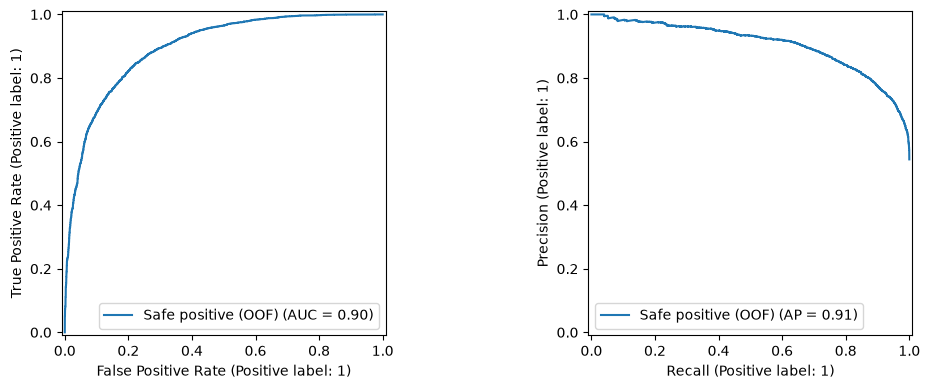

In [5]:
meta=json.loads((DEST/'meta_comparison.json').read_text())
display(pd.DataFrame([{k:q[k] for k in ['name','auc','f1_safe','cross_threshold_f1','accuracy','threshold']} for q in meta]).sort_values('cross_threshold_f1',ascending=False))
print(json.dumps(selection,ensure_ascii=False,indent=2))
inputs=np.load(DEST/'ensemble_inputs.npz'); probabilities=np.load(DEST/'ensemble_predictions.npz')
y=inputs['y'];p=probabilities['oof'];cut=selection['stable_cutoff']
assert abs(f1_score(y,probabilities['cross_threshold_prediction'])-validation['cross_threshold_f1'])<1e-12
fig,axes=plt.subplots(1,2,figsize=(11,4))
RocCurveDisplay.from_predictions(y,p,ax=axes[0],name='Safe positive (OOF)')
PrecisionRecallDisplay.from_predictions(y,p,ax=axes[1],name='Safe positive (OOF)')
fig.tight_layout();plt.show()

## 5. 제출 파일·변경 행 검증

`output=1`은비독성이고0은독성이다. 원본규약label을학습했으므로최종에서뒤집지않는다. 기존1차와새파일의SMILES·순서는같다. 모델이정한확률cutoff를적용했으며테스트의positive비율을미리강제하지않았다.

PASS: 927행·2열·SMILES 원문/순서·positive규약·저장예측일치
1차와 바뀐 행: 32


output
1    565
0    362
Name: 예측 행 수, dtype: int64

,SMILES,previous_output,improved_output,safe_score,distance_to_threshold
0,CC1CCN(CC1)c2ccc3cc(CCN4CCC[C@H]4C)ccc3n2,0,1,0.453386,0.051298
1,FC(F)(F)Oc1ccccc1CC(N2CCNCC2)c3ccccc3,0,1,0.410766,0.008678
2,Cc1cc(C)nc(Nc2cc(NC[C@@H](N)CC(F)F)cnc2C(=O)N)c1,0,1,0.472558,0.070469
3,CC(C)\C(=N\c1ccnc2cc(Cl)ccc12)\NCCCN3CCCCC3,0,1,0.546103,0.144015
4,CNCc1cc(ccc1Oc2ccc(Cl)c(Cl)c2)S(=O)(=O)NC,0,1,0.437799,0.035710
5,C[C@@H]1CCCN1CCN2CCc3cc(Oc4ccc(cn4)C#N)ccc3C2=O,0,1,0.409204,0.007116
6,CC(C)CNC(=O)c1ccc(cc1)C2=CC3(CCNCC3)Oc4ccccc24,0,1,0.452647,0.050558
7,Oc1ccc(cn1)c2cc3sc(nc3cn2)N4CCC(CC4)N5CCCCC5,0,1,0.469832,0.067744
8,Cc1cc(ccc1c2ccnc(NCc3n[nH]c(c3Cl)c4ccccn4)c2)C#N,0,1,0.498462,0.096373
9,Oc1ccc(cc1)c2onc(c2)[C@@H]3CCC[C@H]3C(=O)NC4(C...,0,1,0.407388,0.005300


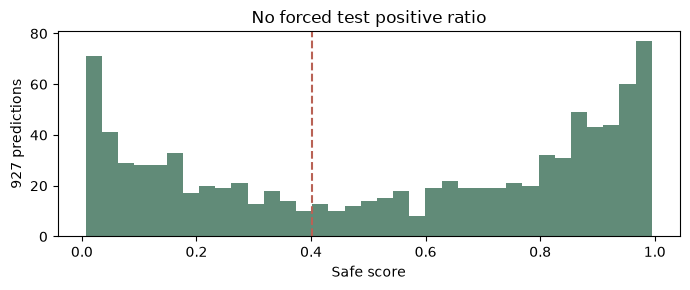

In [6]:
template=pd.read_csv(ROOT/'01_원본자료/predict_output_홍길동.csv')
previous=pd.read_csv(DEST/'1차백업/predict_output_서혁인.csv')
submission=pd.read_csv(DEST/'제출용/predict_output_서혁인.csv')
assert list(submission)==list(template)==['SMILES','output']
assert submission.shape==template.shape==(927,2)
assert submission.SMILES.equals(template.SMILES) and previous.SMILES.equals(submission.SMILES)
assert np.array_equal(submission.output,probabilities['test']>=cut)
assert set(submission.output)<={0,1}
print('PASS: 927행·2열·SMILES 원문/순서·positive규약·저장예측일치')
print('1차와 바뀐 행:',int((submission.output!=previous.output).sum()))
display(submission.output.value_counts().rename('예측 행 수'))
display(pd.read_csv(DEST/'changed_predictions.csv').head(12))
fig,ax=plt.subplots(figsize=(7,3))
ax.hist(probabilities['test'],bins=35,color='#618b78');ax.axvline(cut,color='#b96255',linestyle='--')
ax.set(xlabel='Safe score',ylabel='927 predictions',title='No forced test positive ratio')
plt.tight_layout();plt.show()

## 6. 재현 경로

전체실행코드는 `08_재개선/improve.py`다. 기존 `.venv_eda`를사용한다. `self-check`, `tune`, `xgb`, `multi-kernel`, `repeat --names lgb_leaf31_lowchild lgb_leaf31 --seed 2026`, `connected`, `ensemble` 순서로수행할수있다. 새학습은로컬이며API를호출하지않는다.

OOF/test메타입력, 사용한캐시의hash, 파라미터, fold/seed를보관한다. 원본데이터를덮어쓰지않는다. 이노트북은 완료된학습결과를읽고검증하며자동학습/외부제출을하지않는다.

[개선 결과](../08_재개선/개선_결과.md) · [실험 계획](../08_재개선/실험계획.md)